In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("fraud_oracle.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
df.head()

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [14]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 15420
Number of columns: 33


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Month                 15420 non-null  str  
 1   WeekOfMonth           15420 non-null  int64
 2   DayOfWeek             15420 non-null  str  
 3   Make                  15420 non-null  str  
 4   AccidentArea          15420 non-null  str  
 5   DayOfWeekClaimed      15420 non-null  str  
 6   MonthClaimed          15420 non-null  str  
 7   WeekOfMonthClaimed    15420 non-null  int64
 8   Sex                   15420 non-null  str  
 9   MaritalStatus         15420 non-null  str  
 10  Age                   15420 non-null  int64
 11  Fault                 15420 non-null  str  
 12  PolicyType            15420 non-null  str  
 13  VehicleCategory       15420 non-null  str  
 14  VehiclePrice          15420 non-null  str  
 15  FraudFound_P          15420 non-null  int64
 16  PolicyNumber   

In [16]:
df.replace("?", np.nan, inplace=True)

print("Missing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Series([], dtype: int64)

Total missing values: 0


In [17]:
print(df["FraudFound_P"].value_counts())

print("\nFraud percentage:")
print(df["FraudFound_P"].value_counts(normalize=True) * 100)

FraudFound_P
0    14497
1      923
Name: count, dtype: int64

Fraud percentage:
FraudFound_P
0    94.014267
1     5.985733
Name: proportion, dtype: float64


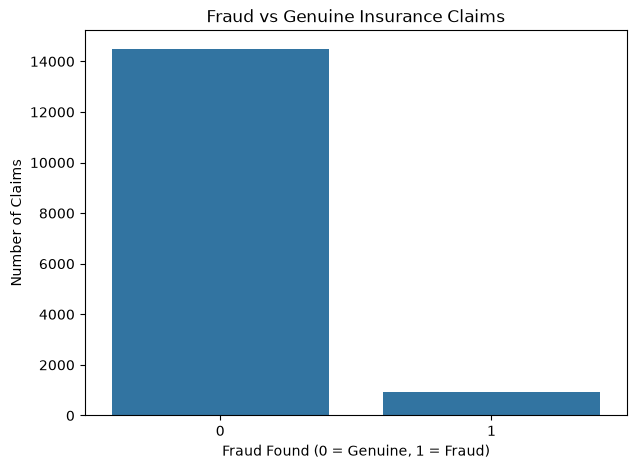

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="FraudFound_P")

plt.title("Fraud vs Genuine Insurance Claims")
plt.xlabel("Fraud Found (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Claims")

plt.show()

In [19]:
# Replace question marks with missing values
df.replace("?", np.nan, inplace=True)

# Check missing values
missing = df.isnull().sum()

print("Missing values:")
print(missing[missing > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values:
Series([], dtype: int64)

Total missing values: 0


In [20]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [21]:
print(df["FraudFound_P"].value_counts())

print("\nPercentage distribution:")
print(df["FraudFound_P"].value_counts(normalize=True) * 100)

FraudFound_P
0    14497
1      923
Name: count, dtype: int64

Percentage distribution:
FraudFound_P
0    94.014267
1     5.985733
Name: proportion, dtype: float64


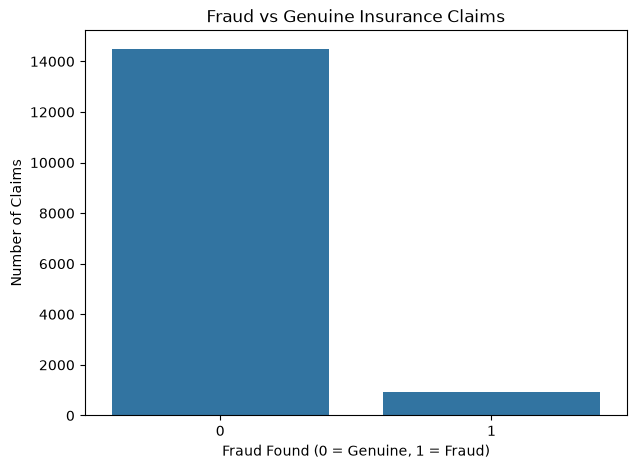

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="FraudFound_P")

plt.title("Fraud vs Genuine Insurance Claims")
plt.xlabel("Fraud Found (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Claims")

plt.show()

In [23]:
# Separate input features and target variable
X = df.drop("FraudFound_P", axis=1)
y = df["FraudFound_P"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (15420, 32)
Target shape: (15420,)


In [24]:
# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    exclude=["int64", "float64"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Year']

Categorical features:
['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (12336, 32)
Testing data: (3084, 32)

Training target distribution:
FraudFound_P
0    11598
1      738
Name: count, dtype: int64

Testing target distribution:
FraudFound_P
0    2899
1     185
Name: count, dtype: int64


In [26]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [27]:
# Fit on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (12336, 148)
Processed testing data: (3084, 148)


In [28]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [29]:
# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (12336, 148)
Testing data shape: (3084, 148)


In [30]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

Before SMOTE:
FraudFound_P
0    11598
1      738
Name: count, dtype: int64

After SMOTE:
FraudFound_P
0    11598
1    11598
Name: count, dtype: int64


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("All four models initialized successfully!")

All four models initialized successfully!


In [32]:
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_balanced, y_train_balanced)

    trained_models[name] = model

    print(f"{name} trained successfully!\n")

print("All models trained successfully!")

Training Logistic Regression...


c:\Users\Mohan\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training AdaBoost...
AdaBoost trained successfully!

Training XGBoost...
XGBoost trained successfully!

All models trained successfully!


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

results = []

for name, model in trained_models.items():

    # Predict classes
    y_pred = model.predict(X_test_processed)

    # Predict fraud probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Calculate metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{name}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Genuine", "Fraudulent"],
        zero_division=0
    ))
    


Logistic Regression
              precision    recall  f1-score   support

     Genuine       0.98      0.65      0.78      2899
  Fraudulent       0.13      0.82      0.23       185

    accuracy                           0.66      3084
   macro avg       0.56      0.74      0.51      3084
weighted avg       0.93      0.66      0.75      3084


Random Forest
              precision    recall  f1-score   support

     Genuine       0.94      1.00      0.97      2899
  Fraudulent       0.67      0.01      0.02       185

    accuracy                           0.94      3084
   macro avg       0.80      0.51      0.50      3084
weighted avg       0.92      0.94      0.91      3084


AdaBoost
              precision    recall  f1-score   support

     Genuine       0.98      0.71      0.82      2899
  Fraudulent       0.14      0.74      0.23       185

    accuracy                           0.71      3084
   macro avg       0.56      0.72      0.53      3084
weighted avg       0.93     

In [34]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.663424,0.131374,0.821622,0.226528,0.801037
1,Random Forest,0.940337,0.666667,0.010811,0.021277,0.831129
2,AdaBoost,0.710117,0.139369,0.740541,0.234589,0.795791
3,XGBoost,0.941634,1.000000,0.027027,0.052632,0.840445


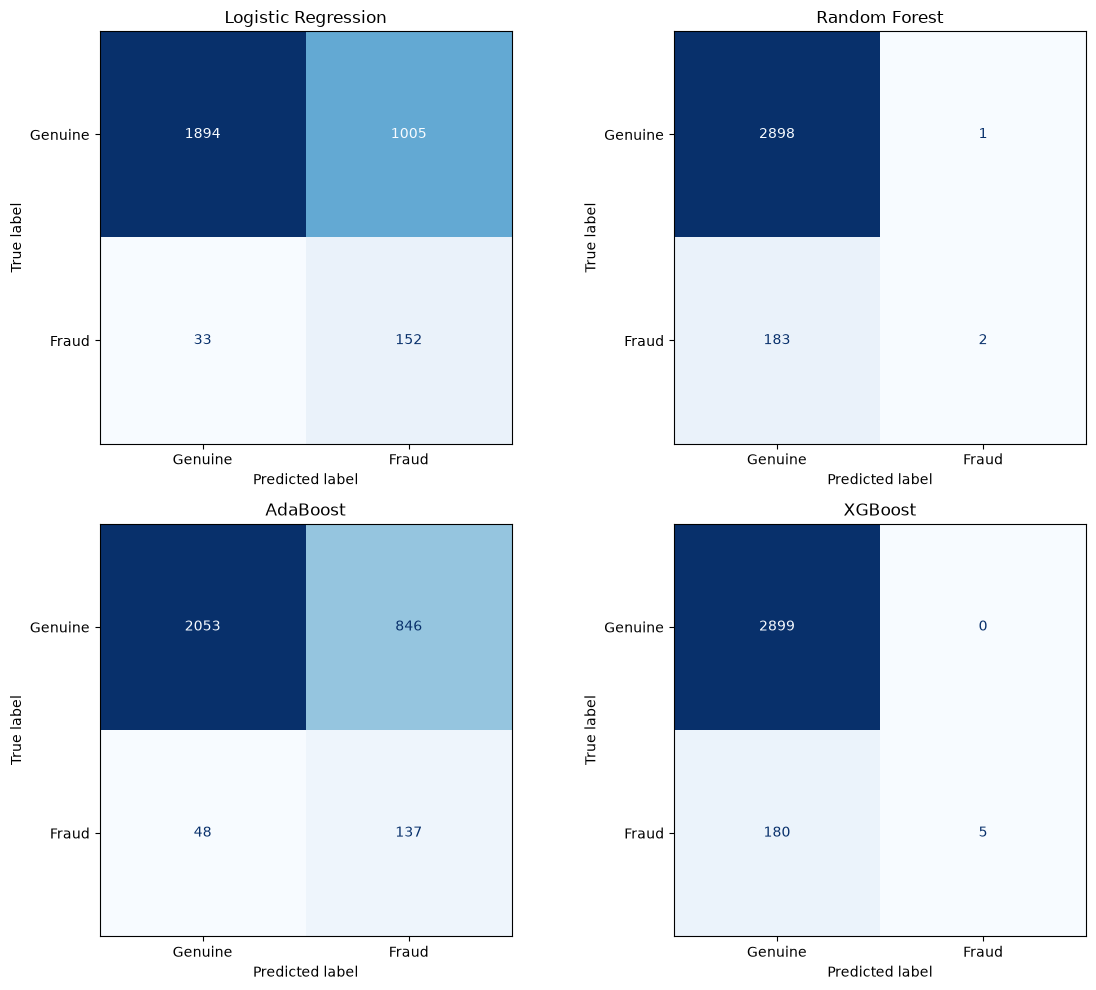

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.ravel(), trained_models.items()):
    y_pred = model.predict(X_test_processed)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Genuine", "Fraud"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

model = trained_models["Logistic Regression"]

y_prob = model.predict_proba(X_test_processed)[:, 1]

for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(
        y_test, y_pred_threshold, zero_division=0
    ))
    print("Recall:", recall_score(
        y_test, y_pred_threshold, zero_division=0
    ))
    print("F1-score:", f1_score(
        y_test, y_pred_threshold, zero_division=0
    ))


Threshold: 0.2
Precision: 0.1257905832747716
Recall: 0.9675675675675676
F1-score: 0.22263681592039802

Threshold: 0.3
Precision: 0.1282798833819242
Recall: 0.9513513513513514
F1-score: 0.22607578676942838

Threshold: 0.4
Precision: 0.1296583850931677
Recall: 0.9027027027027027
F1-score: 0.22674813306177868

Threshold: 0.5
Precision: 0.1313742437337943
Recall: 0.8216216216216217
F1-score: 0.22652757078986588

Threshold: 0.6
Precision: 0.14163090128755365
Recall: 0.7135135135135136
F1-score: 0.23634735899731424


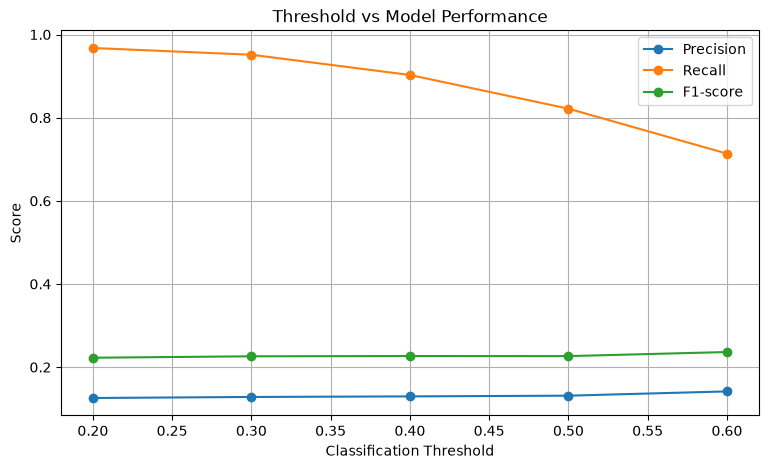

In [37]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision_values.append(
        precision_score(y_test, y_pred_threshold, zero_division=0)
    )
    recall_values.append(
        recall_score(y_test, y_pred_threshold, zero_division=0)
    )
    f1_values.append(
        f1_score(y_test, y_pred_threshold, zero_division=0)
    )

plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision_values, marker="o", label="Precision")
plt.plot(thresholds, recall_values, marker="o", label="Recall")
plt.plot(thresholds, f1_values, marker="o", label="F1-score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold vs Model Performance")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

import numpy as np
import pandas as pd

print("Hyperparameter tuning libraries imported successfully!")

Hyperparameter tuning libraries imported successfully!


In [39]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

tuning_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Tuning pipeline created successfully!")

Tuning pipeline created successfully!


In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

param_grids = {
    "Logistic Regression": {
        "classifier": LogisticRegression(
            max_iter=2000,
            random_state=42
        ),
        "params": {
            "classifier__C": [0.01, 0.1, 1, 10, 100],
            "classifier__solver": ["lbfgs", "liblinear"],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "Random Forest": {
        "classifier": RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        "params": {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [None, 10, 20, 30],
            "classifier__min_samples_split": [2, 5, 10],
            "classifier__min_samples_leaf": [1, 2, 4],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "AdaBoost": {
        "classifier": AdaBoostClassifier(
            random_state=42
        ),
        "params": {
            "classifier__n_estimators": [50, 100, 150, 200],
            "classifier__learning_rate": [0.01, 0.1, 0.5, 1.0]
        }
    },

    "XGBoost": {
        "classifier": XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ),
        "params": {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [3, 4, 5, 6],
            "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
            "classifier__subsample": [0.7, 0.8, 1.0],
            "classifier__colsample_bytree": [0.7, 0.8, 1.0]
        }
    }
}

print("Hyperparameter search spaces defined!")

Hyperparameter search spaces defined!


In [41]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tuning_results = []
best_estimators = {}

for name, config in param_grids.items():

    print(f"\nTuning {name}...")

    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", config["classifier"])
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["params"],
        n_iter=10,
        scoring="f1",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    search.fit(X_train, y_train)

    best_estimators[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1-Score": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV F1-score:", search.best_score_)
    print("Best parameters:", search.best_params_)

print("\nAll four models tuned successfully!")


Tuning Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV F1-score: 0.22570460649270885
Best parameters: {'classifier__solver': 'liblinear', 'classifier__class_weight': None, 'classifier__C': 0.1}

Tuning Random Forest...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV F1-score: 0.2216442546905392
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}

Tuning AdaBoost...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV F1-score: 0.22148473605009608
Best parameters: {'classifier__n_estimators': 100, 'classifier__learning_rate': 0.5}

Tuning XGBoost...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV F1-score: 0.40128613861911244
Best parameters: {'classifier__subsample': 1.0, 'classifier__n_estimators': 200, 'classifier__max_depth': 5, 'classifier__lea

In [42]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="Best CV F1-Score",
    ascending=False
).reset_index(drop=True)

tuning_df

,Model,Best CV F1-Score,Best Parameters
0,XGBoost,0.401286,"{'classifier__subsample': 1.0, 'classifier__n_..."
1,Logistic Regression,0.225705,"{'classifier__solver': 'liblinear', 'classifie..."
2,Random Forest,0.221644,"{'classifier__n_estimators': 100, 'classifier_..."
3,AdaBoost,0.221485,"{'classifier__n_estimators': 100, 'classifier_..."


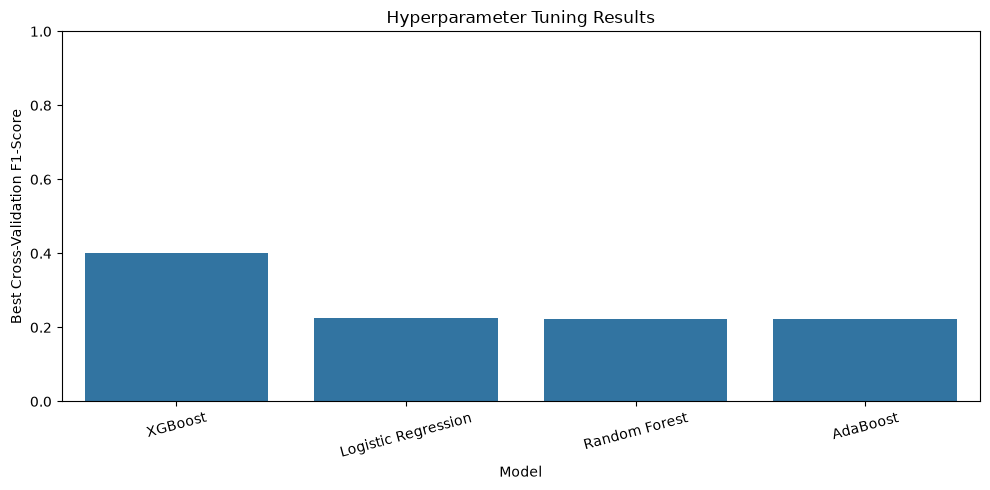

In [43]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuning_df,
    x="Model",
    y="Best CV F1-Score"
)

plt.title("Hyperparameter Tuning Results")
plt.xlabel("Model")
plt.ylabel("Best Cross-Validation F1-Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [44]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Subtraining data:", X_subtrain.shape)
print("Validation data:", X_val.shape)

Subtraining data: (9868, 32)
Validation data: (2468, 32)


In [45]:
best_xgb = best_estimators["XGBoost"]

# Create a fresh model with the tuned parameters
xgb_params = best_xgb.named_steps["classifier"].get_params()

xgb_validation_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(**xgb_params))
])

xgb_validation_model.fit(X_subtrain, y_subtrain)

print("Tuned XGBoost trained on subtraining data!")

Tuned XGBoost trained on subtraining data!


In [46]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_val_prob = xgb_validation_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.1, 0.91, 0.05):
    y_val_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1-Score
0,0.10,0.434932,0.858108,0.577273
1,0.15,0.522523,0.783784,0.627027
2,0.20,0.597765,0.722973,0.654434
3,0.25,0.619355,0.648649,0.633663
4,0.30,0.666667,0.581081,0.620939
5,0.35,0.675676,0.506757,0.579151
6,0.40,0.700000,0.425676,0.529412
7,0.45,0.724638,0.337838,0.460829
8,0.50,0.730769,0.256757,0.380000
9,0.55,0.714286,0.202703,0.315789


In [47]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Selected threshold:", best_threshold)
print(best_threshold_row)

Selected threshold: 0.2
Threshold    0.200000
Precision    0.597765
Recall       0.722973
F1-Score     0.654434
Name: 2, dtype: float64


In [48]:
# Get the best XGBoost hyperparameters
best_xgb_params = best_estimators["XGBoost"].named_steps[
    "classifier"
].get_params()

# Create the final pipeline
final_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(**best_xgb_params))
])

# Train using the full training dataset
final_model.fit(X_train, y_train)

print("Final XGBoost model trained successfully!")

Final XGBoost model trained successfully!


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities on the untouched test set
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the validation-selected threshold
y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("Final Test Results")
print("Threshold:", best_threshold)
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Genuine", "Fraudulent"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Final Test Results
Threshold: 0.2
Accuracy: 0.954928664072633
Precision: 0.6055045871559633
Recall: 0.7135135135135136
F1-score: 0.6550868486352357
ROC-AUC: 0.9629620652042177

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.98      0.97      0.98      2899
  Fraudulent       0.61      0.71      0.66       185

    accuracy                           0.95      3084
   macro avg       0.79      0.84      0.82      3084
weighted avg       0.96      0.95      0.96      3084


Confusion Matrix:
[[2813   86]
 [  53  132]]


In [50]:
import pickle

# Bundle all required components
model_bundle = {
    "model": final_model,
    "model_name": "XGBoost",
    "threshold": best_threshold,
    "features": X_train.columns.tolist()
}

# Save the bundle
with open("best_fraud_model.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("Model saved successfully!")

Model saved successfully!


In [51]:
import os

file_path = "best_fraud_model.pkl"

if os.path.exists(file_path):
    print("Pickle file created successfully!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
else:
    print("File not found!")

Pickle file created successfully!
File size: 626.67 KB


In [52]:
with open("best_fraud_model.pkl", "rb") as file:
    loaded_bundle = pickle.load(file)

loaded_model = loaded_bundle["model"]
loaded_threshold = loaded_bundle["threshold"]

# Test one sample from the test dataset
sample = X_test.iloc[[0]]

probability = loaded_model.predict_proba(sample)[0, 1]
prediction = int(probability >= loaded_threshold)

print("Fraud probability:", round(probability, 4))
print("Selected threshold:", loaded_threshold)
print("Prediction:", "Fraudulent" if prediction == 1 else "Genuine")

Fraud probability: 0.0006
Selected threshold: 0.2
Prediction: Genuine
